In [2]:
from gctm_jcgs_simulation_study_helpers import *
import os
import pickle

/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# go up one in working directory to be in the same directory as the mlflow runs
os.chdir("..")

## Overview Notes

- D-Vine and R-Vine Strong have similar AUC as in submitted GTM paper, C-Vine is better then before
- Still order of D-Vine best, then R-Vine then C-Vine so story stays
- convergence in Strong not the case in normal rather the case of the vines
- precision entry seems better then the conditional correlation (why?)
- 20D and 50D confirm vine difficulty order and also that strong is more difficult
- note that for higher dimensions due to Indepedence tree = 3 we have more imbalance hence the auc can only be compared within the dimensionality not between (tends to get larger with imbalance), if we need other metrics we can compute using the tables we stored in each run

## Plotting Functions

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


def compute_stats_from_df(
    df: pd.DataFrame,
    metric_col: str,
    lower_quantile: float = 20,
    upper_quantile: float = 80,
) -> tuple:
    """Compute mean and quantile bounds for a single experiment df."""
    values = df[metric_col].dropna().values
    mean   = np.mean(values)
    lower  = np.percentile(values, lower_quantile)
    upper  = np.percentile(values, upper_quantile)
    return mean, lower, upper


def create_comparison_plot(
    experiment_dfs: dict,               # {sample_size (int) : df}
    metric_cols: list,                  # e.g. ["metrics.auc_c", "metrics.auc_p"]
    metric_labels: list = None,         # e.g. ["AUC C-Vine", "AUC Precision"]
    colors: list        = None,
    lower_quantile: float = 20,
    upper_quantile: float = 80,
    y_min: float = None,
    y_max: float = None,
    xlabel: str  = "Sample Size",
    ylabel: str  = "AUC",
    title:  str  = "",
    legend: bool = True,
    figsize: tuple = (6, 4),
):
    """
    Plot metric statistics across sample sizes for multiple metrics.

    Parameters
    ----------
    experiment_dfs : dict
        Keys   = sample sizes (int), e.g. {125: df_125, 500: df_500, ...}
        Values = DataFrames with metric columns
    metric_cols    : list of column names to plot (one line per metric)
    metric_labels  : display names for each metric (defaults to metric_cols)
    colors         : one color per metric
    """

    # ── Defaults ──────────────────────────────────────────────────────────────
    if metric_labels is None:
        metric_labels = metric_cols

    if colors is None:
        default_colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"]
        colors = default_colors[: len(metric_cols)]

    # ── Sort by sample size ───────────────────────────────────────────────────
    sorted_sizes = sorted(experiment_dfs.keys())
    x_positions  = np.arange(len(sorted_sizes))

    # Offset so multiple metrics don't overlap
    n_metrics = len(metric_cols)
    offsets   = np.linspace(-0.2, 0.2, n_metrics) if n_metrics > 1 else [0.0]

    # ── Plot ──────────────────────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=figsize)

    for metric_col, label, color, offset in zip(metric_cols, metric_labels, colors, offsets):

        means, lowers, uppers = [], [], []

        for size in sorted_sizes:
            df = experiment_dfs[size]

            if metric_col not in df.columns:
                raise ValueError(f"Column '{metric_col}' not found in df for size {size}. "
                                 f"Available: {df.columns.tolist()}")

            mean, lower, upper = compute_stats_from_df(
                df, metric_col, lower_quantile, upper_quantile
            )
            means.append(mean)
            lowers.append(lower)
            uppers.append(upper)

        means  = np.array(means)
        lowers = np.array(lowers)
        uppers = np.array(uppers)

        ax.errorbar(
            x_positions + offset,
            means,
            yerr=[means - lowers, uppers - means],
            label=label,
            fmt="o",
            linestyle="",
            capsize=5,
            color=color,
        )

    # ── Formatting ────────────────────────────────────────────────────────────
    ax.set_xticks(x_positions)
    ax.set_xticklabels(sorted_sizes)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(True, which="both", linestyle="--", linewidth=0.5)

    if title:
        ax.set_title(title)
    if legend:
        ax.legend()
    if y_min is not None and y_max is not None:
        ax.set_ylim(y_min, y_max)

    plt.tight_layout()
    plt.show()

## AUC Results

### C-Vine

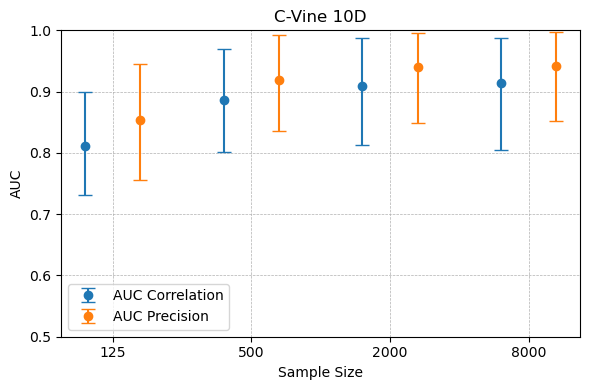

In [39]:

# ── Load experiments ──────────────────────────────────────────────────────────
experiment_names = {
    125  : "ggm_cvine_10D_125obs",
    500  : "ggm_cvine_10D_500obs",
    2000 : "ggm_cvine_10D_2000obs",
    8000 : "ggm_cvine_10D_8000obs",
}

metric_cols = ["metrics.auc_c", "metrics.auc_p"]

experiment_dfs = {}

for sample_size, exp_name in experiment_names.items():
    experiment    = mlflow.get_experiment_by_name(exp_name)
    df_runs       = mlflow.search_runs([experiment.experiment_id])
    # Keep only relevant columns
    experiment_dfs[sample_size] = df_runs[metric_cols + ["tags.seed_value"]]

# ── Plot ──────────────────────────────────────────────────────────────────────
create_comparison_plot(
    experiment_dfs  = experiment_dfs,
    metric_cols     = metric_cols,
    metric_labels   = ["AUC Correlation", "AUC Precision"],
    colors          = ["#1f77b4", "#ff7f0e"],
    lower_quantile  = 5,
    upper_quantile  = 95,
    y_min           = 0.5,
    y_max           = 1.0,
    xlabel          = "Sample Size",
    ylabel          = "AUC",
    title           = "C-Vine 10D",
    legend          = True,
)

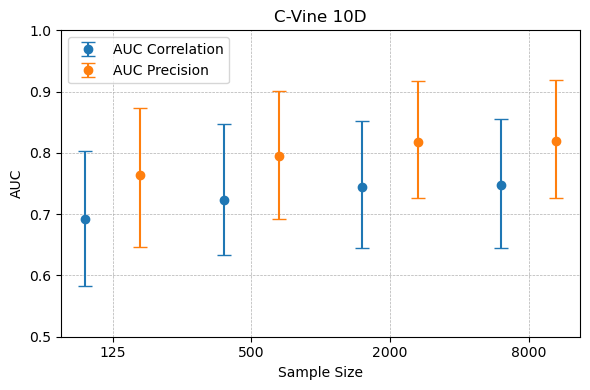

In [38]:

# ── Load experiments ──────────────────────────────────────────────────────────
experiment_names = {
    125  : "ggm_cvine_strong_10D_125obs",
    500  : "ggm_cvine_strong_10D_500obs",
    2000 : "ggm_cvine_strong_10D_2000obs",
    8000 : "ggm_cvine_strong_10D_8000obs",
}

metric_cols = ["metrics.auc_c", "metrics.auc_p"]

experiment_dfs = {}

for sample_size, exp_name in experiment_names.items():
    experiment    = mlflow.get_experiment_by_name(exp_name)
    df_runs       = mlflow.search_runs([experiment.experiment_id])
    # Keep only relevant columns
    experiment_dfs[sample_size] = df_runs[metric_cols + ["tags.seed_value"]]

# ── Plot ──────────────────────────────────────────────────────────────────────
create_comparison_plot(
    experiment_dfs  = experiment_dfs,
    metric_cols     = metric_cols,
    metric_labels   = ["AUC Correlation", "AUC Precision"],
    colors          = ["#1f77b4", "#ff7f0e"],
    lower_quantile  = 5,
    upper_quantile  = 95,
    y_min           = 0.5,
    y_max           = 1.0,
    xlabel          = "Sample Size",
    ylabel          = "AUC",
    title           = "C-Vine 10D",
    legend          = True,
)

### D-Vine

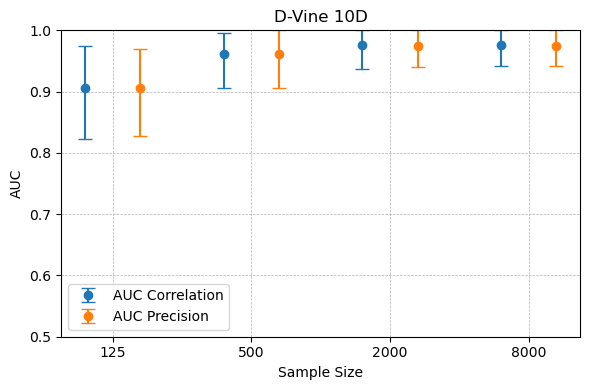

In [37]:

# ── Load experiments ──────────────────────────────────────────────────────────
experiment_names = {
    125  : "ggm_dvine_10D_125obs",
    500  : "ggm_dvine_10D_500obs",
    2000 : "ggm_dvine_10D_2000obs",
    8000 : "ggm_dvine_10D_8000obs",
}

metric_cols = ["metrics.auc_c", "metrics.auc_p"]

experiment_dfs = {}

for sample_size, exp_name in experiment_names.items():
    experiment    = mlflow.get_experiment_by_name(exp_name)
    df_runs       = mlflow.search_runs([experiment.experiment_id])
    # Keep only relevant columns
    experiment_dfs[sample_size] = df_runs[metric_cols + ["tags.seed_value"]]

# ── Plot ──────────────────────────────────────────────────────────────────────
create_comparison_plot(
    experiment_dfs  = experiment_dfs,
    metric_cols     = metric_cols,
    metric_labels   = ["AUC Correlation", "AUC Precision"],
    colors          = ["#1f77b4", "#ff7f0e"],
    lower_quantile  = 5,
    upper_quantile  = 95,
    y_min           = 0.5,
    y_max           = 1.0,
    xlabel          = "Sample Size",
    ylabel          = "AUC",
    title           = "D-Vine 10D",
    legend          = True,
)

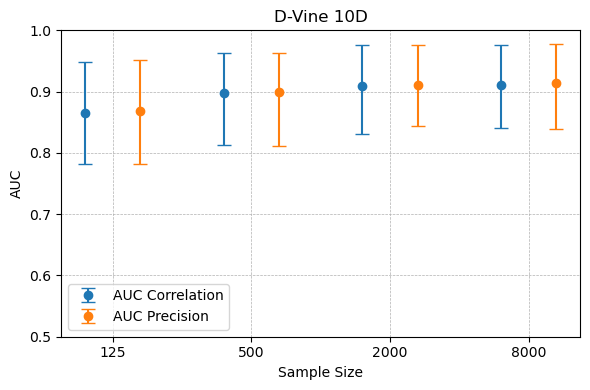

In [36]:

# ── Load experiments ──────────────────────────────────────────────────────────
experiment_names = {
    125  : "ggm_dvine_strong_10D_125obs",
    500  : "ggm_dvine_strong_10D_500obs",
    2000 : "ggm_dvine_strong_10D_2000obs",
    8000 : "ggm_dvine_strong_10D_8000obs",
}

metric_cols = ["metrics.auc_c", "metrics.auc_p"]

experiment_dfs = {}

for sample_size, exp_name in experiment_names.items():
    experiment    = mlflow.get_experiment_by_name(exp_name)
    df_runs       = mlflow.search_runs([experiment.experiment_id])
    # Keep only relevant columns
    experiment_dfs[sample_size] = df_runs[metric_cols + ["tags.seed_value"]]

# ── Plot ──────────────────────────────────────────────────────────────────────
create_comparison_plot(
    experiment_dfs  = experiment_dfs,
    metric_cols     = metric_cols,
    metric_labels   = ["AUC Correlation", "AUC Precision"],
    colors          = ["#1f77b4", "#ff7f0e"],
    lower_quantile  = 5,
    upper_quantile  = 95,
    y_min           = 0.5,
    y_max           = 1.0,
    xlabel          = "Sample Size",
    ylabel          = "AUC",
    title           = "D-Vine 10D",
    legend          = True,
)

### R-Vine

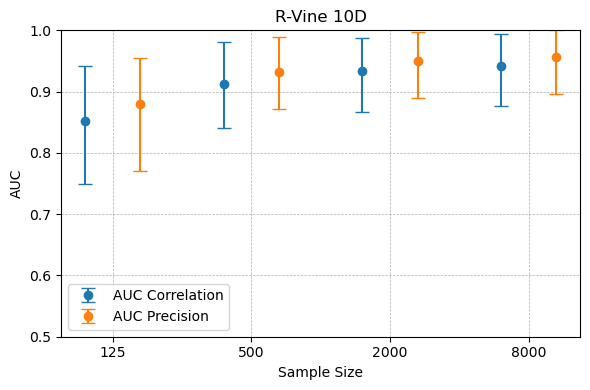

In [35]:

# ── Load experiments ──────────────────────────────────────────────────────────
experiment_names = {
    125  : "ggm_rvine_10D_125obs",
    500  : "ggm_rvine_10D_500obs",
    2000 : "ggm_rvine_10D_2000obs",
    8000 : "ggm_rvine_10D_8000obs",
}

metric_cols = ["metrics.auc_c", "metrics.auc_p"]

experiment_dfs = {}

for sample_size, exp_name in experiment_names.items():
    experiment    = mlflow.get_experiment_by_name(exp_name)
    df_runs       = mlflow.search_runs([experiment.experiment_id])
    # Keep only relevant columns
    experiment_dfs[sample_size] = df_runs[metric_cols + ["tags.seed_value"]]

# ── Plot ──────────────────────────────────────────────────────────────────────
create_comparison_plot(
    experiment_dfs  = experiment_dfs,
    metric_cols     = metric_cols,
    metric_labels   = ["AUC Correlation", "AUC Precision"],
    colors          = ["#1f77b4", "#ff7f0e"],
    lower_quantile  = 5,
    upper_quantile  = 95,
    y_min           = 0.5,
    y_max           = 1.0,
    xlabel          = "Sample Size",
    ylabel          = "AUC",
    title           = "R-Vine 10D",
    legend          = True,
)

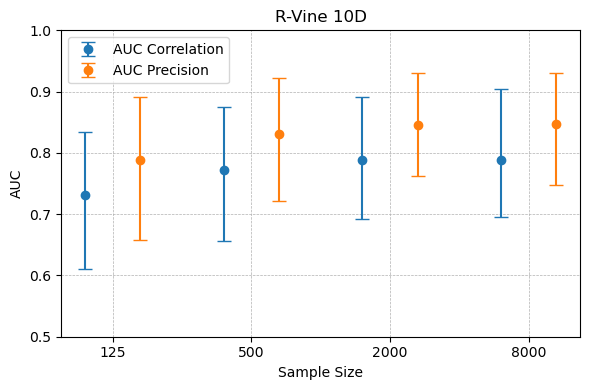

In [46]:

# ── Load experiments ──────────────────────────────────────────────────────────
experiment_names = {
    125  : "ggm_rvine_strong_10D_125obs",
    500  : "ggm_rvine_strong_10D_500obs",
    2000 : "ggm_rvine_strong_10D_2000obs",
    8000 : "ggm_rvine_strong_10D_8000obs",
}

metric_cols = ["metrics.auc_c", "metrics.auc_p"]

experiment_dfs = {}

for sample_size, exp_name in experiment_names.items():
    experiment    = mlflow.get_experiment_by_name(exp_name)
    df_runs       = mlflow.search_runs([experiment.experiment_id])
    # Keep only relevant columns
    experiment_dfs[sample_size] = df_runs[metric_cols + ["tags.seed_value"]]

# ── Plot ──────────────────────────────────────────────────────────────────────
create_comparison_plot(
    experiment_dfs  = experiment_dfs,
    metric_cols     = metric_cols,
    metric_labels   = ["AUC Correlation", "AUC Precision"],
    colors          = ["#1f77b4", "#ff7f0e"],
    lower_quantile  = 5,
    upper_quantile  = 95,
    y_min           = 0.5,
    y_max           = 1.0,
    xlabel          = "Sample Size",
    ylabel          = "AUC",
    title           = "R-Vine 10D",
    legend          = True,
)

### 20 Dimensional D-R-C-Vine

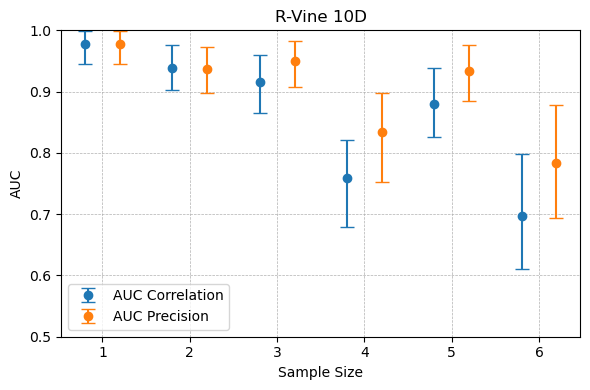

In [47]:

# ── Load experiments ──────────────────────────────────────────────────────────
experiment_names = {
    1  : "ggm_dvine_20D_2000obs",
    2  : "ggm_dvine_strong_20D_2000obs",
    3  : "ggm_rvine_20D_2000obs",
    4  : "ggm_rvine_strong_20D_2000obs",
    5  : "ggm_cvine_20D_2000obs",
    6  : "ggm_cvine_strong_20D_2000obs",
}

metric_cols = ["metrics.auc_c", "metrics.auc_p"]

experiment_dfs = {}

for sample_size, exp_name in experiment_names.items():
    experiment    = mlflow.get_experiment_by_name(exp_name)
    df_runs       = mlflow.search_runs([experiment.experiment_id])
    # Keep only relevant columns
    experiment_dfs[sample_size] = df_runs[metric_cols + ["tags.seed_value"]]

# ── Plot ──────────────────────────────────────────────────────────────────────
create_comparison_plot(
    experiment_dfs  = experiment_dfs,
    metric_cols     = metric_cols,
    metric_labels   = ["AUC Correlation", "AUC Precision"],
    colors          = ["#1f77b4", "#ff7f0e"],
    lower_quantile  = 5,
    upper_quantile  = 95,
    y_min           = 0.5,
    y_max           = 1.0,
    xlabel          = "Sample Size",
    ylabel          = "AUC",
    title           = "R-Vine 10D",
    legend          = True,
)

### 50 Dimensional D-R-C-Vine

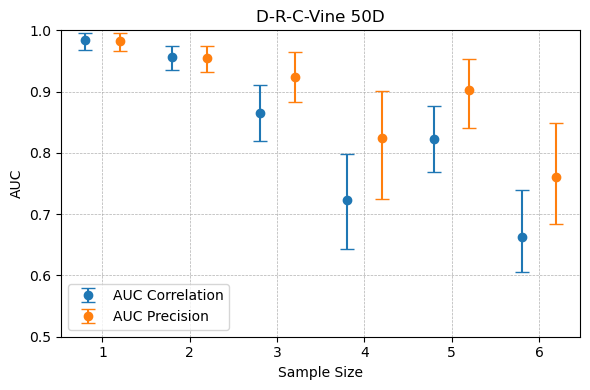

In [67]:

# ── Load experiments ──────────────────────────────────────────────────────────
experiment_names = {
    1  : "ggm_dvine_50D_2000obs",
    2  : "ggm_dvine_strong_50D_2000obs",
    3  : "ggm_rvine_50D_2000obs",
    4  : "ggm_rvine_strong_50D_2000obs",
    5  : "ggm_cvine_50D_2000obs",
    6  : "ggm_cvine_strong_50D_2000obs",
}

metric_cols = ["metrics.auc_c", "metrics.auc_p"]

experiment_dfs = {}

for sample_size, exp_name in experiment_names.items():
    experiment    = mlflow.get_experiment_by_name(exp_name)
    df_runs       = mlflow.search_runs([experiment.experiment_id])
    # Keep only relevant columns
    experiment_dfs[sample_size] = df_runs[metric_cols + ["tags.seed_value"]]

# ── Plot ──────────────────────────────────────────────────────────────────────
create_comparison_plot(
    experiment_dfs  = experiment_dfs,
    metric_cols     = metric_cols,
    metric_labels   = ["AUC Correlation", "AUC Precision"],
    colors          = ["#1f77b4", "#ff7f0e"],
    lower_quantile  = 5,
    upper_quantile  = 95,
    y_min           = 0.5,
    y_max           = 1.0,
    xlabel          = "Sample Size",
    ylabel          = "AUC",
    title           = "D-R-C-Vine 50D",
    legend          = True,
)

### 100 Dimensional D-R-C-Vine

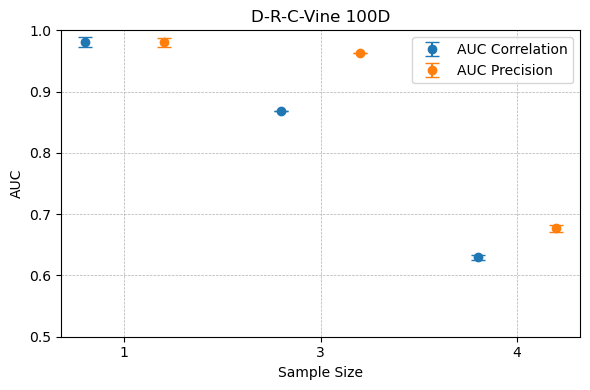

In [66]:

# ── Load experiments ──────────────────────────────────────────────────────────
experiment_names = {
    1  : "ggm_dvine_100D_2000obs",
    #2  : "ggm_dvine_strong_100D_2000obs",
    3  : "ggm_rvine_100D_2000obs",
    4  : "ggm_rvine_strong_100D_2000obs",
    #5  : "ggm_cvine_100D_2000obs",
    #6  : "ggm_cvine_strong_100D_2000obs",
}

metric_cols = ["metrics.auc_c", "metrics.auc_p"]

experiment_dfs = {}

for sample_size, exp_name in experiment_names.items():
    experiment    = mlflow.get_experiment_by_name(exp_name)
    df_runs       = mlflow.search_runs([experiment.experiment_id])
    # Keep only relevant columns
    experiment_dfs[sample_size] = df_runs[metric_cols + ["tags.seed_value"]]

# ── Plot ──────────────────────────────────────────────────────────────────────
create_comparison_plot(
    experiment_dfs  = experiment_dfs,
    metric_cols     = metric_cols,
    metric_labels   = ["AUC Correlation", "AUC Precision"],
    colors          = ["#1f77b4", "#ff7f0e"],
    lower_quantile  = 5,
    upper_quantile  = 95,
    y_min           = 0.5,
    y_max           = 1.0,
    xlabel          = "Sample Size",
    ylabel          = "AUC",
    title           = "D-R-C-Vine 100D",
    legend          = True,
)